# Notebook 2b — Extracción de la variable *cochera* con IA (OE5 · bloque R8)

**Objetivo.** Construir un tratamiento **binario** (cochera incluida en el alquiler: sí/no) a partir del texto de los avisos, como pide la guía del asesor.

**Diseño (pensado para minimizar el costo en tokens):**
1. Se trabaja **solo con la muestra analítica y geocodificación `ROOFTOP`** (dirección exacta): las demás filas no se usarán, así que no se procesan.
2. **Regex** busca menciones de cochera, estacionamiento, parqueo, parking, garaje, etc. Si **no hay mención**, el aviso se clasifica como *sin cochera* **sin llamar a la API**.
3. Si hay mención, solo se envía el **fragmento** `texto[x-200 : x+200]` alrededor de cada mención (sin salirse de los límites; los fragmentos que se solapan se unen).
4. Antes de enviar, se **enmascaran** teléfonos, correos y enlaces.
5. Modelo `gpt-4.1-mini-2025-04-14` (versión fechada, no cambia con el tiempo), **temperatura 0** y **salida JSON con esquema fijo**:
   `{"cochera": "si"|"no", "tipo": "incluida"|"costo_extra"|"no_tiene"|"ambigua", "precio_extra": 0 | monto | null, "moneda", "incluida_explicita", "num_cocheras", "motivo"}`.
6. Cada respuesta se guarda en una **caché local** (`csv/cochera_llm_cache.jsonl`, privada): volver a ejecutar el notebook no vuelve a pagar.

**Supuestos (declarados):**
* Si el aviso **no menciona** cochera, se asume que **no tiene**. Es el supuesto más débil: un aviso puede omitirla (además, el 72 % de las descripciones termina en "Leer descripción completa").
* Si tiene cochera y **no** indica un pago adicional, se asume **incluida** en el precio (`precio_extra = 0`). La variable `incluida_explicita` marca cuándo el texto lo dice de forma literal, para una definición estricta alternativa.
* Si indica un monto o un pago aparte, es **costo extra**.

**Definición del tratamiento (fijada antes de estimar):**
* `T = 1`: cochera incluida (`tipo = incluida`).
* `T = 0`: sin cochera (sin mención o `tipo = no_tiene`).
* Excluidos: `costo_extra` (el precio no incluye la cochera: otra versión del tratamiento) y `ambigua`.
* Alternativa estricta: `T = 1` solo si `incluida_explicita = true`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from causal_utils import *
import extraccion_ia as ia

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ORIGEN = "notebook2b_extraccion_ia.ipynb"
base = pd.read_csv("../csv/data_causal_base.csv")
raw = pd.read_csv("../data/data_wrangling_20250324_202229.csv")

# Reconstruye el id_aviso del notebook 2 (orden del crudo tras quitar núcleo faltante) y lo verifica
r = raw.dropna(subset=["dormitorios", "banos", "area", "precio", "distrito"]).reset_index(drop=True)
r["id_aviso"] = np.arange(len(r))
chk = base.merge(r[["id_aviso", "precio", "area"]], on="id_aviso", suffixes=("", "_r"))
assert (chk["precio"] == chk["precio_r"]).all() and (chk["area"] == chk["area_r"]).all()

d = muestra(base)
print("Muestra analítica:", len(d), "| precisión:", d["precision"].value_counts().to_dict())
d = d[d["precision"] == "ROOFTOP"].merge(r[["id_aviso", "descripcion"]], on="id_aviso", how="left")
print("Solo ROOFTOP:", len(d), "| sin descripción:", int(d["descripcion"].isna().sum()))

Muestra analítica: 2220 | precisión: {'ROOFTOP': 2220}
Solo ROOFTOP: 2220 | sin descripción: 0


## 1. Pre-filtro con regex y fragmentos

In [2]:
d["texto"] = d["descripcion"].fillna("")
d["n_menciones"] = d["texto"].map(lambda s: len(ia.PATRON.findall(s)))
d["menciona"] = (d["n_menciones"] > 0).astype(int)
d["fragmento"] = np.where(d["menciona"] == 1, d["texto"].map(ia.ventanas).map(ia.enmascarar), "")
d["cortada"] = d["texto"].str.contains("Leer descripción completa", regex=False).astype(int)

pre = pd.DataFrame({
  "concepto": ["Avisos ROOFTOP", "Sin mención de cochera (no se envían a la API)", "Con mención (se envían a la API)",
               "Fragmentos únicos enviados", "Largo medio del fragmento (caracteres)", "Largo medio de la descripción completa",
               "Descripciones que terminan en 'Leer descripción completa'"],
  "valor": [len(d), int((d.menciona == 0).sum()), int(d.menciona.sum()), int(d.loc[d.menciona == 1, "fragmento"].nunique()),
            round(d.loc[d.menciona == 1, "fragmento"].str.len().mean()), round(d["texto"].str.len().mean()), int(d["cortada"].sum())]})
guardar_tabla(pre, "R8_prefiltro", decimales=0, origen=ORIGEN)
pre

,concepto,valor
0,Avisos ROOFTOP,2220
1,Sin mención de cochera (no se envían a la API),659
2,Con mención (se envían a la API),1561
3,Fragmentos únicos enviados,1530
4,Largo medio del fragmento (caracteres),458
5,Largo medio de la descripción completa,1012
6,Descripciones que terminan en 'Leer descripció...,1602


## 2. Extracción con OpenAI (con caché)

El prompt completo y el esquema JSON están en `extraccion_ia.py` (`PROMPT_SISTEMA`, `ESQUEMA`). Se probó primero en un piloto de 25 avisos
y se corrigieron tres errores del prompt v1 (marcar como *ambigua* una cochera sin precio, leer "ALQUILER CON COCHERA $700" como costo extra
y no reconocer "sin cochera, pero se puede alquilar"); la versión usada es la v2.

In [3]:
print("Modelo:", ia.MODELO, "| versión del prompt:", ia.VERSION_PROMPT)
frags = d.loc[d.menciona == 1, "fragmento"].tolist()
regs, nuevas = ia.extraer(frags, hilos=8)
unicos = {r_["clave"]: r_ for r_ in regs}.values()
tin, tout, usd = ia.costo(list(unicos))
print(f"Llamadas nuevas en esta ejecución: {nuevas} | tokens de entrada {tin:,} | salida {tout:,} | costo estimado USD {usd:.3f}")

res = pd.DataFrame([x["resultado"] for x in regs])
llm = d.loc[d.menciona == 1, ["id_aviso"]].reset_index(drop=True).join(res)

Modelo: gpt-4.1-mini-2025-04-14 | versión del prompt: v2
Llamadas nuevas en esta ejecución: 0 | tokens de entrada 1,504,649 | salida 87,622 | costo estimado USD 0.742


In [4]:
# Variables finales (los avisos sin mención no pasan por la API)
sin = d.loc[d.menciona == 0, ["id_aviso"]].assign(cochera="no", tipo="sin_mencion", precio_extra=np.nan, moneda=None,
                                                    incluida_explicita=False, num_cocheras=0, motivo="sin mención en el texto")
co = pd.concat([llm, sin], ignore_index=True)
co.loc[co["tipo"].isin(["no_tiene", "sin_mencion", "ambigua"]), "precio_extra"] = np.nan   # coherencia del JSON
co.loc[co["precio_extra"].fillna(-1) == 0, "moneda"] = None
co["T_cochera"] = np.select([co["tipo"] == "incluida", co["tipo"].isin(["no_tiene", "sin_mencion"])], [1, 0], np.nan)
co["T_cochera_estricta"] = np.select([(co["tipo"] == "incluida") & co["incluida_explicita"],
                                      co["tipo"].isin(["no_tiene", "sin_mencion"])], [1, 0], np.nan)
co = co.merge(d[["id_aviso", "menciona", "cortada"]], on="id_aviso")
co.to_csv("../csv/cochera_extraccion.csv", index=False)     # privado (incluye el motivo con citas del texto)

dist = (co.groupby(["tipo"]).size().rename("N").reset_index()
          .assign(**{"%": lambda t: 100 * t["N"] / t["N"].sum()}))
dist["uso en el análisis"] = dist["tipo"].map({"incluida": "T = 1", "no_tiene": "T = 0", "sin_mencion": "T = 0",
                                               "costo_extra": "excluido", "ambigua": "excluido"})
guardar_tabla(dist, "R8_distribucion", decimales=1, origen=ORIGEN)
display(dist)
print("Tratamiento principal -> T=1:", int((co.T_cochera == 1).sum()), "| T=0:", int((co.T_cochera == 0).sum()),
      "| excluidos:", int(co.T_cochera.isna().sum()))
print("Estricta (incluida explícita) -> T=1:", int((co.T_cochera_estricta == 1).sum()))
ce = co[co.tipo == "costo_extra"]
print("Costo extra con monto:", int(ce.precio_extra.notna().sum()), "| mediana del monto por moneda:",
      ce.groupby("moneda")["precio_extra"].median().to_dict())

,tipo,N,%,uso en el análisis
0,ambigua,19,0.855856,excluido
1,costo_extra,150,6.756757,excluido
2,incluida,1095,49.324324,T = 1
3,no_tiene,297,13.378378,T = 0
4,sin_mencion,659,29.684685,T = 0


Tratamiento principal -> T=1: 1095 | T=0: 956 | excluidos: 169
Estricta (incluida explícita) -> T=1: 155
Costo extra con monto: 110 | mediana del monto por moneda: {'PEN': 250.0, 'USD': 50.0}


## 3. Coherencia regex frente a IA

La regex detecta *menciones*; la IA decide si la mención implica cochera del departamento. Las discrepancias (menciona pero `no_tiene`)
son casos como "no tiene cochera", "estacionamiento de visitas" o "se puede estacionar en la calle": justamente lo que una regex no distingue.

In [5]:
coh = pd.crosstab(co["menciona"].map({1: "menciona", 0: "no menciona"}), co["tipo"])
display(coh)
print("Entre los que mencionan, % que la IA clasifica como 'no_tiene':",
      round(100 * (co.loc[co.menciona == 1, "tipo"] == "no_tiene").mean(), 1))
print("Ejemplos de motivo (no_tiene con mención):")
for m in co.loc[(co.menciona == 1) & (co.tipo == "no_tiene"), "motivo"].head(5):
    print(" -", m)

tipo,ambigua,costo_extra,incluida,no_tiene,sin_mencion
menciona,,,,,
menciona,19,150,1095,297,0
no menciona,0,0,0,0,659


Entre los que mencionan, % que la IA clasifica como 'no_tiene': 19.0
Ejemplos de motivo (no_tiene con mención):
 - No tiene cochera pero hay varias cocheras en alquiler.
 - Texto dice explícitamente 'NO TIENE COCHERA'
 - No cuenta con estacionamiento (hay cocheras disponibles para alquilar en el mismo edificio)
 - El departamento no cuenta con estacionamiento.
 - solo menciona estacionamientos para bicicletas, no cochera para departamento


## 4. Muestra para validación humana (pendiente de etiquetar)

La guía exige medir la calidad de la extracción contra **etiquetas humanas**, no contra otro modelo. Se genera una muestra estratificada de
**250 avisos** con el fragmento (o la descripción completa, si no hubo mención) y columnas vacías para etiquetar **sin ver la predicción**.
Cuando se complete `csv/validacion_cochera_etiquetada.csv`, la celda siguiente calcula precisión, recall, F1 y kappa.

In [6]:
rng = np.random.default_rng(SEED)
estr = {"incluida": 110, "no_tiene": 50, "costo_extra": 30, "ambigua": 20, "sin_mencion": 40}
partes = []
for t, k in estr.items():
    ids = co.loc[co.tipo == t, "id_aviso"].values
    partes.append(rng.choice(ids, size=min(k, len(ids)), replace=False))
val = pd.DataFrame({"id_aviso": np.concatenate(partes)}).merge(d[["id_aviso", "fragmento", "texto"]], on="id_aviso")
val["texto_a_revisar"] = np.where(val["fragmento"] != "", val["fragmento"], val["texto"].map(ia.enmascarar))
val = val[["id_aviso", "texto_a_revisar"]].sample(frac=1, random_state=SEED).reset_index(drop=True)
val["etiqueta_cochera (si/no)"] = ""; val["etiqueta_tipo (incluida/costo_extra/no_tiene/ambigua)"] = ""; val["notas"] = ""
val.to_csv("../csv/validacion_cochera_para_etiquetar.csv", index=False, encoding="utf-8-sig")
print("Muestra de validación:", len(val), "avisos -> csv/validacion_cochera_para_etiquetar.csv")

Muestra de validación: 249 avisos -> csv/validacion_cochera_para_etiquetar.csv


In [7]:
from pathlib import Path
ruta = Path("../csv/validacion_cochera_etiquetada.csv")
if ruta.exists():
    from sklearn.metrics import classification_report, cohen_kappa_score
    et = pd.read_csv(ruta).merge(co[["id_aviso", "cochera", "tipo"]], on="id_aviso")
    et = et[et["etiqueta_cochera (si/no)"].isin(["si", "no"])]
    print(classification_report(et["etiqueta_cochera (si/no)"], et["cochera"], digits=3))
    print("kappa de Cohen:", round(cohen_kappa_score(et["etiqueta_cochera (si/no)"], et["cochera"]), 3))
else:
    print("Validación humana pendiente: etiquetar csv/validacion_cochera_para_etiquetar.csv y guardarlo como validacion_cochera_etiquetada.csv")

Validación humana pendiente: etiquetar csv/validacion_cochera_para_etiquetar.csv y guardarlo como validacion_cochera_etiquetada.csv


## 5. Perfil de los grupos de tratamiento

,T_cochera,N,precio_mediano,area_mediana,banos_medio,pct_clase1
0,Sin cochera (T=0),956,2197.5,65.0,1.577406,31.903766
1,Cochera incluida (T=1),1095,3200.0,96.0,2.078539,55.981735


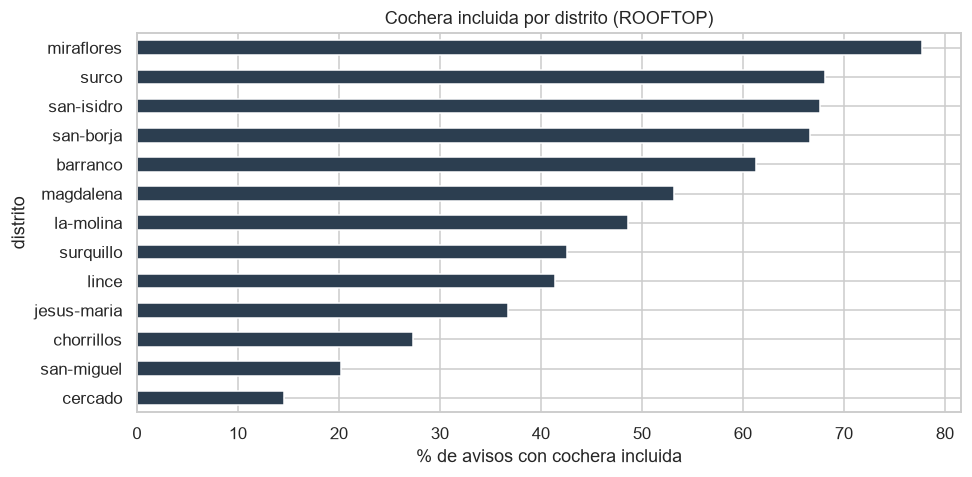

In [8]:
m = d.merge(co[["id_aviso", "tipo", "T_cochera"]], on="id_aviso")
perf = (m.dropna(subset=["T_cochera"]).groupby("T_cochera")
          .agg(N=("precio", "size"), precio_mediano=("precio", "median"), area_mediana=("area", "median"),
               banos_medio=("banos", "mean"), pct_clase1=("distrito_clase", lambda x: 100 * (x == "clase1").mean()))
          .reset_index())
perf["T_cochera"] = perf["T_cochera"].map({0.0: "Sin cochera (T=0)", 1.0: "Cochera incluida (T=1)"})
guardar_tabla(perf, "R8_perfil_grupos", decimales=1, origen=ORIGEN)
display(perf)
por_dist = m.dropna(subset=["T_cochera"]).groupby("distrito")["T_cochera"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5)); (100 * por_dist).plot.barh(ax=ax, color="#2c3e50")
ax.set_xlabel("% de avisos con cochera incluida"); ax.set_title("Cochera incluida por distrito (ROOFTOP)")
plt.tight_layout(); plt.savefig(FIG / "F8_cochera_distrito.png", bbox_inches="tight"); plt.show()

## 6. Conclusiones de la extracción

* La regex reduce las llamadas a la API a los avisos que mencionan cochera, y cada llamada envía solo los fragmentos relevantes.
* La IA distingue lo que la regex no puede: "no tiene cochera", estacionamiento de visitas o en la calle, y cocheras con costo aparte.
* **Pendiente:** validar con etiquetas humanas (`csv/validacion_cochera_para_etiquetar.csv`). Hasta entonces, la medición se considera **exploratoria**.
* El tratamiento principal (incluida frente a sin cochera) se usa en `notebook3b_efecto_cochera.ipynb`.